A simple model featuring XCylinders and XPlanes.

Note the lack of specifying "surface_id" when calling the OpenMC object constructors. Unlike in MCNP, it is generally not advised to manually identify surface ids in OpenMC. The same goes for cell and universe id numbers (though there may be cases where this is required).

In [1]:
%run -i 'clean_script.py'
import openmc
model = openmc.model.Model()

In [54]:
materials = openmc.Materials()
materials.export_to_xml()

In [29]:
# Surface definitions
s1 = openmc.XPlane(x0=0)
s2 = openmc.XCylinder(r=2)
s3 = openmc.XPlane(x0=2)
s4 = openmc.XCylinder(r=3)
s5 = openmc.XPlane(x0=6)

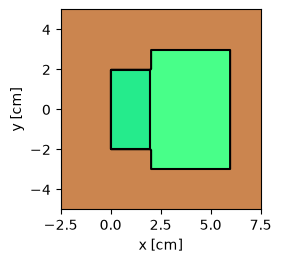

In [33]:
# Cell definitions
c1 = openmc.Cell(fill=None,region=(-s2 & +s1 & -s3))
c2 = openmc.Cell(fill=None,region=(-s4 & +s3 & -s5))
c3 = openmc.Cell(fill=None,region=(~(c1.region) & ~(c2.region)))

geometry=openmc.Geometry([c1,c2,c3])
geometry.plot(origin=(2.5,0,0),width=(10,10),color_by='cell',outline=True)
model.geometry = geometry
model.settings = openmc.Settings()

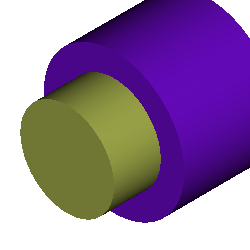

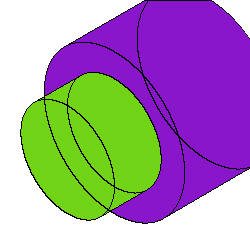

In [51]:
plots = openmc.Plots()
px = (250,250)
solidray = openmc.SolidRayTracePlot()
solidray.pixels=px
solidray.horizontal_field_of_view=0.5
solidray.color_by='cell'
solidray.camera_position=(-500,-500,500)
solidray.look_at = (2.5,0,0)
solidray.opaque_domains=[c1,c2]
plots.append(solidray)

wireframe = openmc.WireframeRayTracePlot()
wireframe.pixels=px
wireframe.horizontal_field_of_view=0.5
wireframe.color_by='cell'
wireframe.camera_position=(-500,-500,500)
wireframe.look_at = (2.5,0,0)
plots.append(wireframe)

model.plots= plots
model.export_to_xml()
openmc.plot_inline(model.plots)

In [52]:
model.export_to_xml()

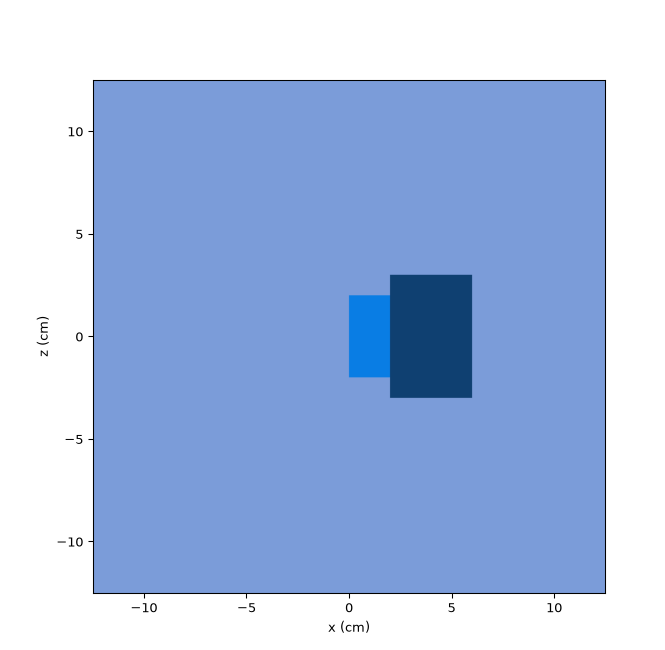